In [1]:
!pip install -q kagglehub

import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import kagglehub

np.random.seed(42)
tf.random.set_seed(42)

print("Tools loaded. TensorFlow version:", tf.__version__)

Tools loaded. TensorFlow version: 2.21.0


In [2]:
dataset_path = kagglehub.dataset_download("priemshpathirana/fabric-stain-dataset")
print("Downloaded to:", dataset_path)

100%|██████████| 415M/415M [00:06<00:00, 69.7MB/s]

Extracting files...


Downloaded to: /root/.cache/kagglehub/datasets/priemshpathirana/fabric-stain-dataset/versions/1


In [3]:
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp")

print(f"{'Folder path':<90} | Image count")
print("-" * 110)
folder_counts = {}
for root, dirs, filenames in os.walk(dataset_path):
    images_here = [f for f in filenames if f.lower().endswith(IMAGE_EXTENSIONS)]
    if images_here:
        folder_counts[root] = len(images_here)
        print(f"{root:<90} | {len(images_here)}")

Folder path                                                                                | Image count
--------------------------------------------------------------------------------------------------------------
/root/.cache/kagglehub/datasets/priemshpathirana/fabric-stain-dataset/versions/1/images/defect_free | 68
/root/.cache/kagglehub/datasets/priemshpathirana/fabric-stain-dataset/versions/1/images/stain | 398


In [4]:
STAIN_FOLDER = "/root/.cache/kagglehub/datasets/priemshpathirana/fabric-stain-dataset/versions/1/images/stain"
CLEAN_FOLDER = "/root/.cache/kagglehub/datasets/priemshpathirana/fabric-stain-dataset/versions/1/images/defect_free"

print("Stain folder exists:", os.path.isdir(STAIN_FOLDER))
print("Clean folder exists:", os.path.isdir(CLEAN_FOLDER))

Stain folder exists: True
Clean folder exists: True


In [5]:
IMG_SIZE = 96

def load_images_from_folder(folder, label, limit=None):
    files = sorted([f for f in os.listdir(folder) if f.lower().endswith(IMAGE_EXTENSIONS)])
    if limit is not None:
        rng = np.random.RandomState(42)
        files = list(rng.choice(files, size=min(limit, len(files)), replace=False))
    images, labels = [], []
    for fname in files:
        try:
            img = Image.open(os.path.join(folder, fname)).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
            images.append(np.array(img) / 255.0)
            labels.append(label)
        except Exception as e:
            print(f"Skipped {fname}: {e}")
    return images, labels

clean_images, clean_labels = load_images_from_folder(CLEAN_FOLDER, label=0)  # 0 = Clean
n_clean = len(clean_images)
print(f"Loaded {n_clean} clean images.")

stain_images, stain_labels = load_images_from_folder(STAIN_FOLDER, label=1, limit=n_clean)  # 1 = Stained
print(f"Loaded {len(stain_images)} stained images (balanced to match clean count).")

X = np.array(clean_images + stain_images)
y = np.array(clean_labels + stain_labels)

shuffle_idx = np.random.permutation(len(X))
X, y = X[shuffle_idx], y[shuffle_idx]

print("\nFinal dataset shape:", X.shape)
print("Clean:", int((y == 0).sum()), "| Stained:", int((y == 1).sum()))

Loaded 68 clean images.
Loaded 68 stained images (balanced to match clean count).

Final dataset shape: (136, 96, 96, 3)
Clean: 68 | Stained: 68


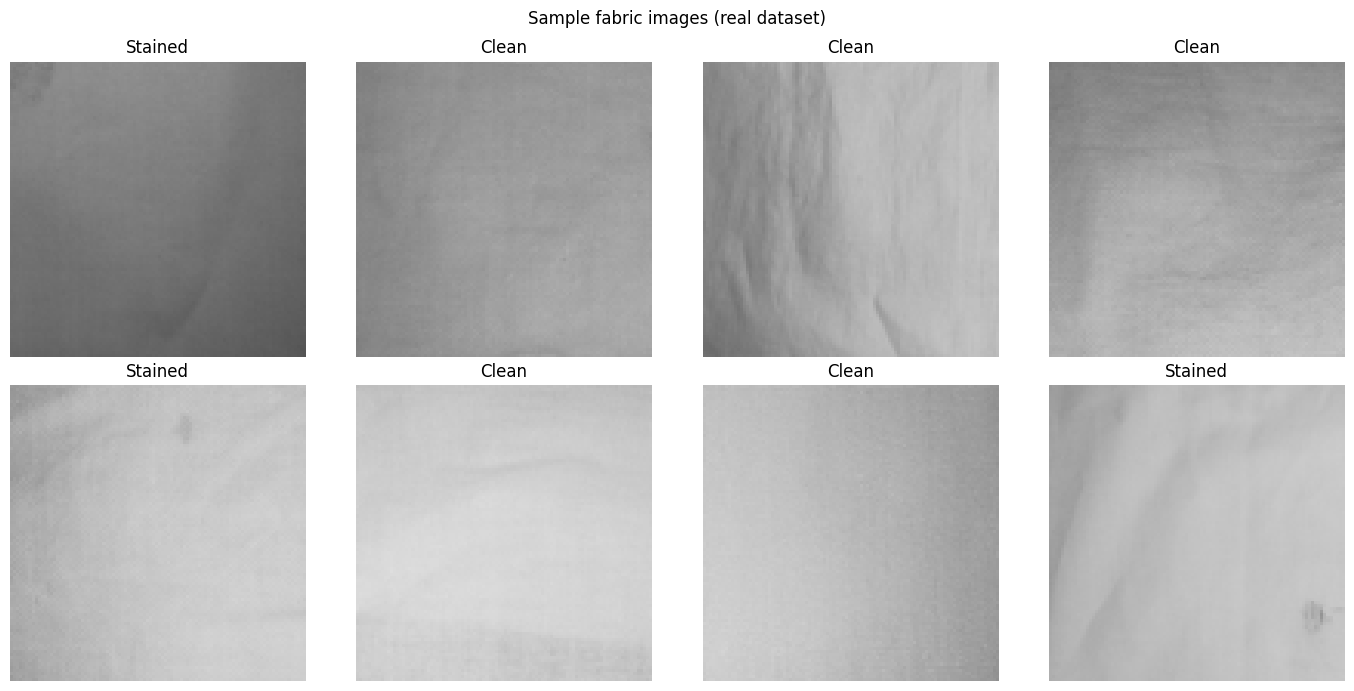

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
labels_text = {0: "Clean", 1: "Stained"}
for ax, img, label in zip(axes.flat, X[:8], y[:8]):
    ax.imshow(img)
    ax.set_title(labels_text[int(label)])
    ax.axis("off")
plt.suptitle("Sample fabric images (real dataset)")
plt.tight_layout()
plt.show()

In [7]:
split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

print("Training images:", len(X_train))
print("Test images:", len(X_test))

Training images: 108
Test images: 28


In [8]:
model = keras.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.Conv2D(16, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid"),  # outputs a number 0-1: probability of "Stained"
])

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 94, 94, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 47, 47, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 45, 45, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 22, 22, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 20, 20, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │       204,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 228,449 (892.38 KB)

 Trainable params: 228,449 (892.38 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
history = model.fit(
    X_train, y_train,
    validation_split=0.15,
    epochs=15,
    batch_size=16,
    verbose=1,
)

Epoch 1/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.4615 - loss: 0.7013 - val_accuracy: 0.4118 - val_loss: 0.7001
Epoch 2/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.5604 - loss: 0.6898 - val_accuracy: 0.4118 - val_loss: 0.7075
Epoch 3/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.6044 - loss: 0.6899 - val_accuracy: 0.4118 - val_loss: 0.7063
Epoch 4/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.5385 - loss: 0.6913 - val_accuracy: 0.4118 - val_loss: 0.6975
Epoch 5/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.5055 - loss: 0.6956 - val_accuracy: 0.4118 - val_loss: 0.7029
Epoch 6/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5495 - loss: 0.6899 - val_accuracy: 0.4118 - val_loss: 0.7022
Epoch 7/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5495 - loss: 0.6914 - val_accuracy: 0.4118 - val_loss: 0.7076
Epoch 8/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5495 - loss: 0.6903 - val_accuracy: 0.4118 - val_loss: 0.7147
E

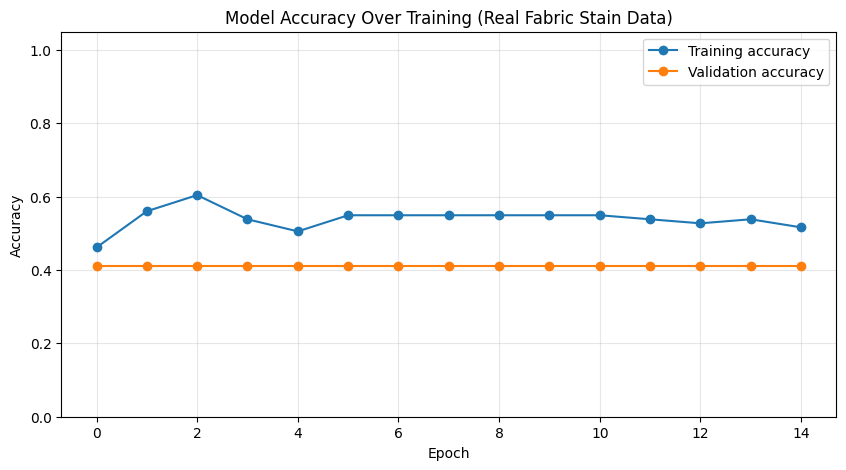

In [10]:
plt.figure(figsize=(10, 5))
plt.plot(history.history["accuracy"], label="Training accuracy", marker="o")
plt.plot(history.history["val_accuracy"], label="Validation accuracy", marker="o")
plt.title("Model Accuracy Over Training (Real Fabric Stain Data)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("training_accuracy.png", dpi=150, bbox_inches="tight")
plt.show()

Test accuracy: 39.3%


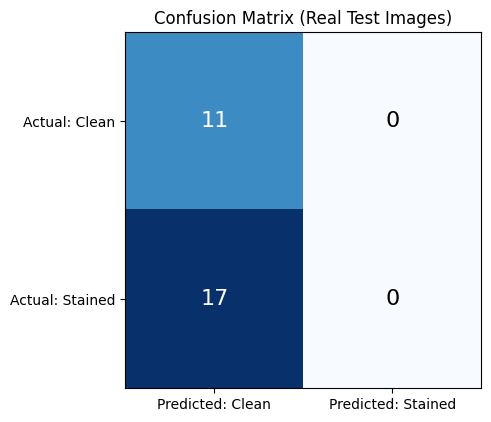


Correctly spotted 0 out of 17 real stained images.
Incorrectly flagged 0 clean images as stained.


In [11]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy: {test_accuracy * 100:.1f}%")

predictions = (model.predict(X_test, verbose=0) > 0.5).astype(int).flatten()

tn = int(((predictions == 0) & (y_test == 0)).sum())
fp = int(((predictions == 1) & (y_test == 0)).sum())
fn = int(((predictions == 0) & (y_test == 1)).sum())
tp = int(((predictions == 1) & (y_test == 1)).sum())

confusion = np.array([[tn, fp], [fn, tp]])

fig, ax = plt.subplots(figsize=(5, 5))
im = ax.imshow(confusion, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_xticklabels(["Predicted: Clean", "Predicted: Stained"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["Actual: Clean", "Actual: Stained"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, confusion[i, j], ha="center", va="center",
                color="white" if confusion[i, j] > confusion.max() / 2 else "black", fontsize=16)
plt.title("Confusion Matrix (Real Test Images)")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\nCorrectly spotted {tp} out of {tp + fn} real stained images.")
print(f"Incorrectly flagged {fp} clean images as stained.")

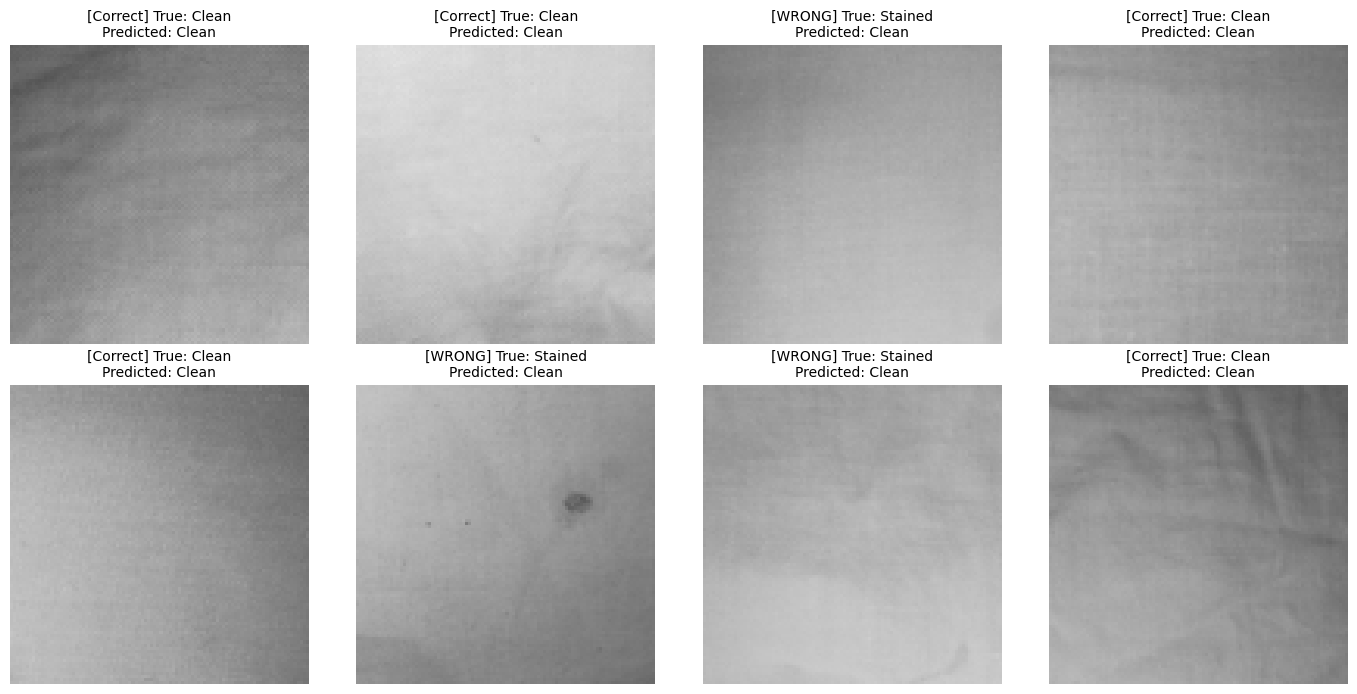

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
labels_text = {0: "Clean", 1: "Stained"}
for ax, img, true_label, pred_label in zip(axes.flat, X_test[:8], y_test[:8], predictions[:8]):
    ax.imshow(img)
    correct = "Correct" if true_label == pred_label else "WRONG"
    ax.set_title(f"[{correct}] True: {labels_text[int(true_label)]}\nPredicted: {labels_text[int(pred_label)]}", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.savefig("sample_predictions.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
from google.colab import files

files.download("training_accuracy.png")
files.download("confusion_matrix.png")
files.download("sample_predictions.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>